# Klasifikasi Sentimen Ujaran Kebencian Terhadap Agama Islam Pada Platform Twitter — Improved Notebook

Proyek asli: `skripsi.ipynb` (dasar publikasi JISMAN Journal + aplikasi Streamlit yang sedang live).

**Notebook ini adalah dokumen baru dan terpisah** — `skripsi.ipynb`, `app.py`, `train_model.py`, serta folder
`csv/`, `pickle/`, `png/` yang menjadi backend aplikasi produksi **tidak diubah maupun ditimpa**. Semua artefak
dari notebook ini ditulis ke folder baru `improved/` (`improved/csv/`, `improved/pickle/`, `improved/png/`).

## Kenapa notebook ini dibuat

Saat mereview `skripsi.ipynb`, ditemukan tiga isu metodologis (bukan sekadar gaya penulisan kode):

1. **Label tertimpa** — `dataset.xlsx` sudah punya kolom `kelas` hasil anotasi manusia (`Negatif`/`Positif`).
   Notebook asli menimpa label ini dengan label hasil skoring lexicon buatan sendiri sebelum melatih model,
   sehingga model dilatih/dievaluasi terhadap label yang berbeda dari yang dipakai `app.py` / `train_model.py`.
2. **Stemmer salah bahasa** — `preprocessing.py` memakai `PorterStemmer` (stemmer Bahasa Inggris) pada teks
   Bahasa Indonesia.
3. **Kebocoran data pada pemilihan hyperparameter** — nilai `alpha` terbaik dipilih berdasarkan akurasi pada
   **test set**, lalu model dengan alpha yang dipilih dari test set itu juga yang dilaporkan sebagai hasil akhir.

## Struktur: Track A vs Track B

- **Track A** — mereproduksi metodologi asli **persis seperti aslinya** (label lexicon, `PorterStemmer`, alpha
  dipilih dari akurasi test set) supaya hasilnya tetap bisa dibandingkan apple-to-apple dengan angka yang sudah
  dipublikasikan di README.
- **Track B** — metodologi yang diperbaiki: label ground-truth asli (`kelas`), stemmer Bahasa Indonesia
  (Sastrawi), alpha dipilih lewat 10-fold cross-validation pada training set saja (test set disentuh sekali,
  di akhir, untuk evaluasi jujur). Track B juga menambahkan perbandingan fitur **TF-IDF vs Bag-of-Words**.
- Notebook ditutup dengan bagian perbandingan Track A vs Track B secara langsung.

Dependensi tambahan yang dipakai di sini dan belum ada di `requirements.txt` project: **Sastrawi** (stemmer
Bahasa Indonesia). Install dengan `pip install Sastrawi` bila belum tersedia.

In [1]:
# Jika Sastrawi belum terpasang, uncomment baris berikut:
# !pip install Sastrawi

import importlib
for pkg in ['Sastrawi']:
    if importlib.util.find_spec(pkg.split('.')[0].lower()) is None and importlib.util.find_spec(pkg) is None:
        print(f"Peringatan: paket '{pkg}' tampaknya belum terpasang. Jalankan: pip install {pkg}")


## 1. Setup dan Konfigurasi

Sama seperti notebook asli (seed, logging, struktur direktori), tapi memakai path **relatif terhadap lokasi
notebook** (`pathlib`) alih-alih path Windows hardcoded (`C:\SkripsiFix\...`), dan menulis ke folder baru
`improved/` supaya tidak menyentuh `csv/`, `pickle/`, `png/` yang dipakai aplikasi produksi.

In [2]:
import os
import re
import random
import logging
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import nltk
from nltk.corpus import stopwords

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# ### Seed untuk reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# ### Direktori project (relatif terhadap notebook ini, bukan hardcoded)
BASE_DIR = Path.cwd()
OUT_DIR = BASE_DIR / 'improved'
CSV_DIR = OUT_DIR / 'csv'
PICKLE_DIR = OUT_DIR / 'pickle'
PNG_DIR = OUT_DIR / 'png'
LEXICON_DIR = BASE_DIR / 'lexicon'
DATASET_PATH = BASE_DIR / 'dataset.xlsx'

for d in (CSV_DIR, PICKLE_DIR, PNG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ### Logging
logging.basicConfig(
    filename=str(OUT_DIR / 'process_log.log'),
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filemode='a',
)
logger = logging.getLogger('skripsi_improved')
logger.info('Setup selesai. Semua output ditulis ke %s (folder csv/pickle/png asli tidak disentuh).', OUT_DIR)

print(f'Output notebook ini akan ditulis ke: {OUT_DIR}')
print(f'Folder csv/, pickle/, png/ milik project asli TIDAK akan diubah.')

# ### Konfigurasi bersama Track A & Track B
SPLIT_RATIOS = {'70_30': 0.3, '80_20': 0.2, '90_10': 0.1}


Output notebook ini akan ditulis ke: /home/user/KlasifikasiSentimenTwitter/improved
Folder csv/, pickle/, png/ milik project asli TIDAK akan diubah.


## 2. Memuat dan Mengeksplorasi Data

Titik awal yang sama untuk Track A dan Track B: memuat `dataset.xlsx`, memastikan kolom yang diharapkan ada
(`full_text`, `kelas`), dan menghapus duplikat.

In [3]:
df_raw = pd.read_excel(DATASET_PATH)
print(f'Dataset dimuat: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom.')
print(f'Kolom: {list(df_raw.columns)}')
display(df_raw.head())

assert {'full_text', 'kelas'}.issubset(df_raw.columns), \
    "Dataset diharapkan punya kolom 'full_text' dan 'kelas' (label ground-truth hasil anotasi manusia)."

print('\nDistribusi label ground-truth (kolom kelas asli, dipakai app.py & train_model.py):')
print(df_raw['kelas'].value_counts())

df_base = df_raw.drop_duplicates().reset_index(drop=True)
print(f'\nSetelah menghapus duplikat: {df_base.shape[0]} baris (dari {df_raw.shape[0]}).')

df_base.to_csv(CSV_DIR / 'base_data.csv', index=False)
logger.info('Data dasar (dedup) disimpan: %d baris.', df_base.shape[0])


Dataset dimuat: 1200 baris, 2 kolom.
Kolom: ['full_text', 'kelas']


,full_text,kelas
0,@Buahterlar42596 @aprimayoga19 Jancuk'an Wong ...,Negatif
1,Eng Ing Eeeeng ... Semoga para biadab yg mempe...,Positif
2,@suleizdn @umarfaruqi_SHI @Generasi_MudaNU orm...,Negatif
3,@denismalhotra Mreka kan kturunan yahudi pesek...,Negatif
4,@bctnakal @_faktaindo ajaran islam memang biad...,Negatif



Distribusi label ground-truth (kolom kelas asli, dipakai app.py & train_model.py):
kelas
Negatif    1002
Positif     198
Name: count, dtype: int64

Setelah menghapus duplikat: 1191 baris (dari 1200).


## 3. Preprocessing

Tahap pembersihan teks (URL/mention/hashtag, lowercasing, tokenisasi, stopword removal) **sama** untuk kedua
track — ini bukan bagian yang bermasalah di notebook asli. Yang berbeda adalah **stemmer**:

- **Track A** memakai `PorterStemmer` dari NLTK (stemmer Bahasa Inggris), persis seperti `preprocessing.py`
  pada notebook asli.
- **Track B** memakai **Sastrawi**, stemmer yang dirancang untuk Bahasa Indonesia.

Contoh di bawah menunjukkan perbedaan hasil stemming pada teks yang sama.

In [4]:
nltk.download('stopwords', quiet=True)
STOPWORDS_ID = set(stopwords.words('indonesian'))

def clean_text(text: str) -> str:
    """Menghapus URL, mention, hashtag, dan karakter non-huruf. Sama seperti preprocessing.py asli."""
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'\@\w+|\#', '', text)
    text = re.sub(r'[^A-Za-z\s]', '', text)
    return text

def tokenize_and_clean(text: str):
    cleaned = clean_text(text)
    lower = cleaned.lower()
    tokens = lower.split()
    no_stop = [t for t in tokens if t not in STOPWORDS_ID]
    return cleaned, lower, tokens, no_stop

# ### Track A: PorterStemmer (stemmer Bahasa Inggris, seperti notebook asli)
from nltk.stem import PorterStemmer
_porter = PorterStemmer()

def preprocess_track_a(text: str):
    cleaned, lower, tokens, no_stop = tokenize_and_clean(text)
    stemmed = [_porter.stem(w) for w in no_stop]
    processed = ' '.join(stemmed)
    return processed

# ### Track B: Sastrawi (stemmer Bahasa Indonesia)
_sastrawi_factory = StemmerFactory()
_sastrawi_stemmer = _sastrawi_factory.create_stemmer()

def preprocess_track_b(text: str):
    cleaned, lower, tokens, no_stop = tokenize_and_clean(text)
    stemmed_text = _sastrawi_stemmer.stem(' '.join(no_stop))
    return stemmed_text

print('Melakukan preprocessing Track A (PorterStemmer) dan Track B (Sastrawi)...')
df_base['processed_text_a'] = df_base['full_text'].apply(preprocess_track_a)
df_base['processed_text_b'] = df_base['full_text'].apply(preprocess_track_b)
print('Selesai.')

sample = df_base[['full_text', 'processed_text_a', 'processed_text_b']].head(5)
display(sample)


Melakukan preprocessing Track A (PorterStemmer) dan Track B (Sastrawi)...


Selesai.


,full_text,processed_text_a,processed_text_b
0,@Buahterlar42596 @aprimayoga19 Jancuk'an Wong ...,jancukan iki sopo seng biadab awakmu ta ummat ...,jancukan iki sopo seng biadab awak ta ummat mu...
1,Eng Ing Eeeeng ... Semoga para biadab yg mempe...,eng ing eeeeng semoga biadab yg mempermainkan ...,eng ing eeeeng moga biadab yg main cjh reguler...
2,@suleizdn @umarfaruqi_SHI @Generasi_MudaNU orm...,orma anggap umat islam orma islam musuhnya dun...,ormas anggap umat islam ormas islam musuh duni...
3,@denismalhotra Mreka kan kturunan yahudi pesek...,mreka kturunan yahudi pesek bang islam ktp mre...,mreka kturunan yahudi pesek bang islam ktp mre...
4,@bctnakal @_faktaindo ajaran islam memang biad...,ajaran islam biadab orang kemalangan menghujat...,ajar islam biadab orang malang hujat rahmat li...


## 4. Labeling

- **Track A** mereproduksi fungsi lexicon-scoring dari notebook asli (`load_lexicon`, `determine_class`,
  `assign_classes`) yang membaca `lexicon/positive.tsv` dan `lexicon/negative.tsv`, lalu **menimpa** label
  menjadi `positif`/`negatif` berdasarkan skor lexicon pada `processed_text_a`.
- **Track B** memakai kolom `kelas` asli dari dataset (dinormalisasi huruf kecil) sebagai label — tidak ada
  relabeling.

Tabel di bawah menunjukkan seberapa sering label lexicon (Track A) **tidak sepakat** dengan label ground-truth
(Track B) — ini bukti konkret untuk isu #1 di bagian pendahuluan.

In [5]:
# ### Track A: fungsi lexicon-scoring, direproduksi persis dari notebook asli

def load_lexicon(file_path):
    lexicon_df = pd.read_csv(file_path, sep='\t')
    return dict(zip(lexicon_df['word'], lexicon_df['weight']))

positive_lexicon = load_lexicon(LEXICON_DIR / 'positive.tsv')
negative_lexicon = load_lexicon(LEXICON_DIR / 'negative.tsv')

def determine_class(text, positive_lexicon, negative_lexicon):
    positive_score = 0
    negative_score = 0
    text = text.lower()
    for phrase, weight in positive_lexicon.items():
        phrase_escaped = re.escape(str(phrase).lower())
        matches = re.findall(r'\b{}\b'.format(phrase_escaped), text)
        positive_score += int(weight) * len(matches)
    for phrase, weight in negative_lexicon.items():
        phrase_escaped = re.escape(str(phrase).lower())
        matches = re.findall(r'\b{}\b'.format(phrase_escaped), text)
        negative_score += abs(int(weight)) * len(matches)
    if positive_score > negative_score:
        return 'positif'
    elif negative_score > positive_score:
        return 'negatif'
    else:
        return 'negatif'

df_base['label_track_a'] = df_base['processed_text_a'].apply(
    lambda x: determine_class(x, positive_lexicon, negative_lexicon)
)

# ### Track B: label ground-truth asli, dinormalisasi
df_base['label_track_b'] = df_base['kelas'].str.lower()

print('Distribusi label Track A (lexicon):')
print(df_base['label_track_a'].value_counts())
print('\nDistribusi label Track B (ground-truth):')
print(df_base['label_track_b'].value_counts())

agreement = (df_base['label_track_a'] == df_base['label_track_b'])
print(f"\nKesepakatan label Track A vs Track B: {agreement.mean():.1%} dari {len(df_base)} baris")

disagreement_table = pd.crosstab(
    df_base['label_track_b'], df_base['label_track_a'],
    rownames=['Ground truth (Track B)'], colnames=['Lexicon (Track A)']
)
display(disagreement_table)

df_base.to_csv(CSV_DIR / 'labeled_data.csv', index=False)
logger.info('Label Track A/B dibuat. Kesepakatan: %.1f%%', agreement.mean() * 100)


Distribusi label Track A (lexicon):
label_track_a
positif    641
negatif    550
Name: count, dtype: int64

Distribusi label Track B (ground-truth):
label_track_b
negatif    995
positif    196
Name: count, dtype: int64

Kesepakatan label Track A vs Track B: 49.9% dari 1191 baris


Lexicon (Track A),negatif,positif
Ground truth (Track B),,
negatif,474,521
positif,76,120


## 5. Pembagian Data (Data Splitting)

Stratified split pada tiga rasio (70:30, 80:20, 90:10), sama seperti notebook asli. Dilakukan terpisah per
track karena label dan teks yang dipreproses berbeda: Track A membagi berdasarkan `label_track_a` /
`processed_text_a`, Track B berdasarkan `label_track_b` / `processed_text_b`.

In [6]:
def split_for_track(df, text_col, label_col, test_size, random_state=SEED):
    X = df[text_col]
    y = df[label_col]
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)

splits = {}  # splits[track][ratio_name] = (X_train, X_test, y_train, y_test)

for track, text_col, label_col in [('a', 'processed_text_a', 'label_track_a'),
                                     ('b', 'processed_text_b', 'label_track_b')]:
    splits[track] = {}
    for ratio_name, test_size in SPLIT_RATIOS.items():
        X_train, X_test, y_train, y_test = split_for_track(df_base, text_col, label_col, test_size)
        splits[track][ratio_name] = (X_train, X_test, y_train, y_test)

        train_df = pd.DataFrame({'processed_text': X_train, 'kelas': y_train})
        test_df = pd.DataFrame({'processed_text': X_test, 'kelas': y_test})
        train_df.to_csv(CSV_DIR / f'track_{track}_train_{ratio_name}.csv', index=False)
        test_df.to_csv(CSV_DIR / f'track_{track}_test_{ratio_name}.csv', index=False)

        logger.info('Track %s, rasio %s: train=%d, test=%d', track, ratio_name, len(X_train), len(X_test))

print('Pembagian data selesai untuk Track A dan Track B, rasio:', list(SPLIT_RATIOS.keys()))
for ratio_name in SPLIT_RATIOS:
    _, _, y_train_a, y_test_a = splits['a'][ratio_name]
    _, _, y_train_b, y_test_b = splits['b'][ratio_name]
    print(f"  {ratio_name}: Track A train/test = {len(y_train_a)}/{len(y_test_a)}, "
          f"Track B train/test = {len(y_train_b)}/{len(y_test_b)}")


Pembagian data selesai untuk Track A dan Track B, rasio: ['70_30', '80_20', '90_10']
  70_30: Track A train/test = 833/358, Track B train/test = 833/358
  80_20: Track A train/test = 952/239, Track B train/test = 952/239
  90_10: Track A train/test = 1071/120, Track B train/test = 1071/120


## 6. Ekstraksi Fitur

- **Track A**: hanya `CountVectorizer` (Bag-of-Words), `max_features=1000` — sama seperti notebook asli.
  Satu vectorizer dilatih pada gabungan teks training dari ketiga rasio.
- **Track B**: `CountVectorizer` **dan** `TfidfVectorizer` (`max_features=1000` masing-masing), supaya bisa
  dibandingkan mana yang lebih baik untuk model ini.

In [7]:
def fit_vectorizer(vectorizer_cls, texts, max_features=1000):
    vec = vectorizer_cls(max_features=max_features)
    vec.fit(texts)
    return vec

# ### Track A: satu CountVectorizer, dilatih pada semua teks training (semua rasio digabung)
all_train_texts_a = pd.concat([splits['a'][r][0] for r in SPLIT_RATIOS])
vectorizer_a_bow = fit_vectorizer(CountVectorizer, all_train_texts_a)
with open(PICKLE_DIR / 'track_a_count_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer_a_bow, f)

# ### Track B: CountVectorizer dan TfidfVectorizer, dilatih pada semua teks training Track B
all_train_texts_b = pd.concat([splits['b'][r][0] for r in SPLIT_RATIOS])
vectorizer_b_bow = fit_vectorizer(CountVectorizer, all_train_texts_b)
vectorizer_b_tfidf = fit_vectorizer(TfidfVectorizer, all_train_texts_b)
with open(PICKLE_DIR / 'track_b_count_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer_b_bow, f)
with open(PICKLE_DIR / 'track_b_tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer_b_tfidf, f)

# ### Transformasi ke matriks fitur per rasio
features = {'a': {}, 'b': {}}  # features[track][ratio_name][feature_type] = (X_train, X_test)

for ratio_name in SPLIT_RATIOS:
    X_train_a, X_test_a, _, _ = splits['a'][ratio_name]
    features['a'][ratio_name] = {'bow': (vectorizer_a_bow.transform(X_train_a), vectorizer_a_bow.transform(X_test_a))}

    X_train_b, X_test_b, _, _ = splits['b'][ratio_name]
    features['b'][ratio_name] = {
        'bow': (vectorizer_b_bow.transform(X_train_b), vectorizer_b_bow.transform(X_test_b)),
        'tfidf': (vectorizer_b_tfidf.transform(X_train_b), vectorizer_b_tfidf.transform(X_test_b)),
    }

    for track in ('a', 'b'):
        for feat_type, (Xtr, Xte) in features[track][ratio_name].items():
            with open(PICKLE_DIR / f'track_{track}_{feat_type}_train_{ratio_name}.pkl', 'wb') as f:
                pickle.dump(Xtr, f)
            with open(PICKLE_DIR / f'track_{track}_{feat_type}_test_{ratio_name}.pkl', 'wb') as f:
                pickle.dump(Xte, f)

print('Dimensi fitur (contoh, rasio 80_20):')
print(f"  Track A BoW   : train={features['a']['80_20']['bow'][0].shape}, test={features['a']['80_20']['bow'][1].shape}")
print(f"  Track B BoW   : train={features['b']['80_20']['bow'][0].shape}, test={features['b']['80_20']['bow'][1].shape}")
print(f"  Track B TF-IDF: train={features['b']['80_20']['tfidf'][0].shape}, test={features['b']['80_20']['tfidf'][1].shape}")


Dimensi fitur (contoh, rasio 80_20):
  Track A BoW   : train=(952, 1000), test=(239, 1000)
  Track B BoW   : train=(952, 1000), test=(239, 1000)
  Track B TF-IDF: train=(952, 1000), test=(239, 1000)


## 7. Pelatihan Model dan Pemilihan Hyperparameter

Bagian ini adalah tempat metodologi Track A dan Track B benar-benar berbeda.

**Track A** mereproduksi notebook asli persis: untuk tiap rasio, alpha terbaik dipilih dari **akurasi pada test
set**, dicoba pada dua kelompok nilai (`minimal`: 0.01/0.1/0.8, `maksimal`: 1.0/2.0/3.0) — model dengan alpha
yang "menang" di test set itulah yang dilaporkan. Ini yang disebut kebocoran data pada pemilihan model: test
set dipakai dua kali (memilih model & melaporkan performanya), padahal seharusnya cuma dipakai sekali.

**Track B** memilih alpha lewat **10-fold cross-validation pada training set saja**, dari satu grid gabungan
(`[0.01, 0.1, 0.5, 0.8, 1.0, 2.0, 3.0]`), tanpa menyentuh test set sama sekali. Test set baru dipakai persis
sekali, di akhir, untuk skor akhir yang jujur — dan dijalankan untuk fitur BoW maupun TF-IDF.

In [8]:
def train_and_score(X_train, y_train, X_test, y_test, alpha):
    """Melatih MultinomialNB dan mengevaluasi pada test set. Dipakai bersama oleh kedua track."""
    model = MultinomialNB(alpha=alpha)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    return model, accuracy, report

# ================= Track A: alpha dipilih dari akurasi TEST SET (seperti notebook asli) =================
TRACK_A_TUNING = {'minimal': [0.01, 0.1, 0.8], 'maksimal': [1.0, 2.0, 3.0]}

track_a_results = []   # list of dict: ratio, tuning_type, alpha, accuracy, report
track_a_best = {}      # (ratio, tuning_type) -> dict(model, alpha, accuracy, report)

for ratio_name in SPLIT_RATIOS:
    X_train, X_test = features['a'][ratio_name]['bow']
    _, _, y_train, y_test = splits['a'][ratio_name]

    for tuning_type, alphas in TRACK_A_TUNING.items():
        best = {'alpha': None, 'accuracy': -1, 'model': None, 'report': None}
        for alpha in alphas:
            model, accuracy, report = train_and_score(X_train, y_train, X_test, y_test, alpha)
            track_a_results.append({'ratio': ratio_name, 'tuning_type': tuning_type, 'alpha': alpha,
                                     'accuracy': accuracy})
            if accuracy > best['accuracy']:
                best = {'alpha': alpha, 'accuracy': accuracy, 'model': model, 'report': report}
        track_a_best[(ratio_name, tuning_type)] = best
        with open(PICKLE_DIR / f'track_a_mnb_{tuning_type}_{ratio_name}.pkl', 'wb') as f:
            pickle.dump(best['model'], f)

track_a_results_df = pd.DataFrame(track_a_results)
track_a_results_df.to_csv(CSV_DIR / 'track_a_alpha_sweep.csv', index=False)
print('Track A - ringkasan alpha terbaik (dipilih dari test set) per rasio & tuning:')
for (ratio_name, tuning_type), best in track_a_best.items():
    print(f"  {ratio_name} / {tuning_type}: alpha={best['alpha']}, akurasi(test)={best['accuracy']:.4f}")


Track A - ringkasan alpha terbaik (dipilih dari test set) per rasio & tuning:
  70_30 / minimal: alpha=0.8, akurasi(test)=0.7039
  70_30 / maksimal: alpha=2.0, akurasi(test)=0.7151
  80_20 / minimal: alpha=0.8, akurasi(test)=0.6987
  80_20 / maksimal: alpha=1.0, akurasi(test)=0.6987
  90_10 / minimal: alpha=0.8, akurasi(test)=0.7083
  90_10 / maksimal: alpha=1.0, akurasi(test)=0.6917


In [9]:
# ================= Track B: alpha dipilih via 10-fold CV pada TRAINING SET saja =================
TRACK_B_ALPHA_GRID = [0.01, 0.1, 0.5, 0.8, 1.0, 2.0, 3.0]
N_FOLDS = 10

def select_alpha_by_cv(X_train, y_train, alphas, n_folds=N_FOLDS, seed=SEED):
    """Memilih alpha dengan mean accuracy CV tertinggi pada training set saja (test set tidak disentuh)."""
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    cv_scores = {}
    for alpha in alphas:
        model = MultinomialNB(alpha=alpha)
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
        cv_scores[alpha] = scores
    best_alpha = max(cv_scores, key=lambda a: cv_scores[a].mean())
    return best_alpha, cv_scores

track_b_results = []       # per-alpha CV mean/std, for the sweep table
track_b_best = {}          # (ratio, feature_type) -> dict(alpha, model, accuracy, report, cv_mean, cv_std)
track_b_cv_folds = []      # per-fold metrics for the chosen alpha, for section 8

for ratio_name in SPLIT_RATIOS:
    _, _, y_train, y_test = splits['b'][ratio_name]

    for feat_type in ('bow', 'tfidf'):
        X_train, X_test = features['b'][ratio_name][feat_type]

        best_alpha, cv_scores = select_alpha_by_cv(X_train, y_train, TRACK_B_ALPHA_GRID)
        for alpha, scores in cv_scores.items():
            track_b_results.append({'ratio': ratio_name, 'feature_type': feat_type, 'alpha': alpha,
                                     'cv_mean_accuracy': scores.mean(), 'cv_std_accuracy': scores.std()})

        # Test set is touched exactly once, after alpha is already fixed by CV.
        model, accuracy, report = train_and_score(X_train, y_train, X_test, y_test, best_alpha)
        track_b_best[(ratio_name, feat_type)] = {
            'alpha': best_alpha, 'model': model, 'accuracy': accuracy, 'report': report,
            'cv_mean': cv_scores[best_alpha].mean(), 'cv_std': cv_scores[best_alpha].std(),
        }
        with open(PICKLE_DIR / f'track_b_mnb_{feat_type}_{ratio_name}.pkl', 'wb') as f:
            pickle.dump(model, f)

        for fold_i, score in enumerate(cv_scores[best_alpha], 1):
            track_b_cv_folds.append({'ratio': ratio_name, 'feature_type': feat_type, 'alpha': best_alpha,
                                      'fold': fold_i, 'cv_accuracy': score})

track_b_results_df = pd.DataFrame(track_b_results)
track_b_results_df.to_csv(CSV_DIR / 'track_b_alpha_cv_sweep.csv', index=False)
track_b_cv_folds_df = pd.DataFrame(track_b_cv_folds)
track_b_cv_folds_df.to_csv(CSV_DIR / 'track_b_cv_folds.csv', index=False)

print('Track B - alpha terbaik (dipilih via CV pada training set), lalu skor test set (disentuh sekali):')
for (ratio_name, feat_type), best in track_b_best.items():
    print(f"  {ratio_name} / {feat_type}: alpha={best['alpha']}, CV(train) mean acc={best['cv_mean']:.4f} "
          f"(+/-{best['cv_std']:.4f}), akurasi(test, sekali)={best['accuracy']:.4f}")


Track B - alpha terbaik (dipilih via CV pada training set), lalu skor test set (disentuh sekali):
  70_30 / bow: alpha=3.0, CV(train) mean acc=0.8067 (+/-0.0160), akurasi(test, sekali)=0.8408
  70_30 / tfidf: alpha=2.0, CV(train) mean acc=0.8355 (+/-0.0052), akurasi(test, sekali)=0.8352
  80_20 / bow: alpha=0.01, CV(train) mean acc=0.8099 (+/-0.0254), akurasi(test, sekali)=0.8159
  80_20 / tfidf: alpha=1.0, CV(train) mean acc=0.8351 (+/-0.0046), akurasi(test, sekali)=0.8368
  90_10 / bow: alpha=0.01, CV(train) mean acc=0.8188 (+/-0.0207), akurasi(test, sekali)=0.7917
  90_10 / tfidf: alpha=2.0, CV(train) mean acc=0.8357 (+/-0.0045), akurasi(test, sekali)=0.8333


## 8. Cross-Validation

- **Track A**: mereproduksi urutan notebook asli — 10-fold CV dijalankan **setelah** alpha dipilih dari test
  set (bagian 7), sebagai langkah validasi tambahan yang terpisah. Tetap dipertahankan agar perbandingan
  dengan notebook asli tetap adil.
- **Track B**: CV *adalah* langkah pemilihan alpha di bagian 7 — jadi di sini kita cukup merangkum metrik
  per-fold yang sudah dihitung (precision/recall/F1 macro ditambahkan, bukan cuma akurasi).

In [10]:
# ================= Track A: 10-fold CV dijalankan SETELAH alpha dipilih dari test set =================
from sklearn.model_selection import KFold
from sklearn.metrics import precision_score, recall_score, f1_score

def kfold_cv_metrics(model_alpha, X, y, n_splits=N_FOLDS, seed=SEED):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    X = X.tocsr()
    y = np.asarray(y)
    rows = []
    for fold, (train_idx, test_idx) in enumerate(kf.split(X), 1):
        model = MultinomialNB(alpha=model_alpha)
        model.fit(X[train_idx], y[train_idx])
        y_pred = model.predict(X[test_idx])
        rows.append({
            'fold': fold,
            'accuracy': accuracy_score(y[test_idx], y_pred),
            'precision_macro': precision_score(y[test_idx], y_pred, average='macro', zero_division=0),
            'recall_macro': recall_score(y[test_idx], y_pred, average='macro', zero_division=0),
            'f1_macro': f1_score(y[test_idx], y_pred, average='macro', zero_division=0),
        })
    return pd.DataFrame(rows)

track_a_cv_summary = []
for (ratio_name, tuning_type), best in track_a_best.items():
    X_train, _ = features['a'][ratio_name]['bow']
    _, _, y_train, _ = splits['a'][ratio_name]
    cv_df = kfold_cv_metrics(best['alpha'], X_train, y_train)
    cv_df.to_csv(CSV_DIR / f'track_a_cv_{tuning_type}_{ratio_name}.csv', index=False)
    track_a_cv_summary.append({'ratio': ratio_name, 'tuning_type': tuning_type, 'alpha': best['alpha'],
                                'cv_mean_accuracy': cv_df['accuracy'].mean()})

track_a_cv_summary_df = pd.DataFrame(track_a_cv_summary)
print('Track A - rata-rata akurasi 10-fold CV (dihitung setelah alpha dipilih dari test set):')
display(track_a_cv_summary_df)


Track A - rata-rata akurasi 10-fold CV (dihitung setelah alpha dipilih dari test set):


,ratio,tuning_type,alpha,cv_mean_accuracy
0,70_30,minimal,0.8,0.683219
1,70_30,maksimal,2.0,0.704791
2,80_20,minimal,0.8,0.687061
3,80_20,maksimal,1.0,0.690175
4,90_10,minimal,0.8,0.702111
5,90_10,maksimal,1.0,0.711457


In [11]:
# ================= Track B: ringkasan metrik CV yang sudah dihitung saat pemilihan alpha =================
track_b_cv_summary = (
    track_b_cv_folds_df.groupby(['ratio', 'feature_type', 'alpha'])['cv_accuracy']
    .agg(['mean', 'std']).reset_index()
    .rename(columns={'mean': 'cv_mean_accuracy', 'std': 'cv_std_accuracy'})
)
print('Track B - rata-rata akurasi 10-fold CV (dipakai untuk memilih alpha, test set belum disentuh):')
display(track_b_cv_summary)


Track B - rata-rata akurasi 10-fold CV (dipakai untuk memilih alpha, test set belum disentuh):


,ratio,feature_type,alpha,cv_mean_accuracy,cv_std_accuracy
0,70_30,bow,3.00,0.806684,0.016851
1,70_30,tfidf,2.00,0.835542,0.005475
2,80_20,bow,0.01,0.809923,0.026817
3,80_20,tfidf,1.00,0.835088,0.004893
4,90_10,bow,0.01,0.818847,0.021783
5,90_10,tfidf,2.00,0.835670,0.004716


## 9. Visualisasi

Confusion matrix disimpan sebagai PNG ke `improved/png/` (di notebook asli hanya ditampilkan dengan
`plt.show()`, tidak disimpan). Ditambahkan juga bar chart akurasi untuk Track A (per rasio x tuning-type,
seperti aslinya) dan Track B (per rasio x tipe fitur, BoW vs TF-IDF).

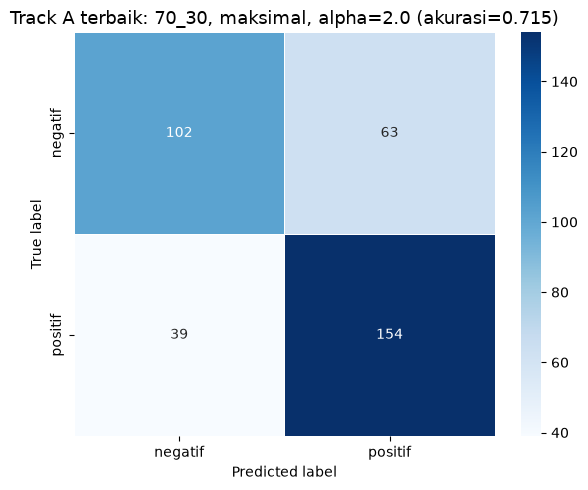

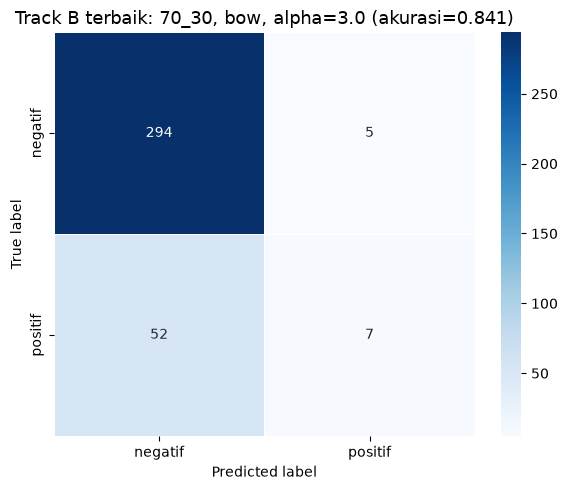

In [12]:
def plot_confusion(y_true, y_pred, classes, title, save_path):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes,
                cbar=True, linewidths=0.5, linecolor='white')
    plt.title(title, fontsize=13)
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()
    plt.close()

# ### Track A: confusion matrix untuk konfigurasi terbaik keseluruhan (akurasi test tertinggi)
track_a_overall_best_key = max(track_a_best, key=lambda k: track_a_best[k]['accuracy'])
best_a = track_a_best[track_a_overall_best_key]
ratio_name, tuning_type = track_a_overall_best_key
_, X_test = features['a'][ratio_name]['bow']
_, _, _, y_test = splits['a'][ratio_name]
y_pred_a = best_a['model'].predict(X_test)
classes_a = sorted(set(y_test) | set(y_pred_a))
plot_confusion(y_test, y_pred_a, classes_a,
               f'Track A terbaik: {ratio_name}, {tuning_type}, alpha={best_a["alpha"]} '
               f'(akurasi={best_a["accuracy"]:.3f})',
               PNG_DIR / 'track_a_best_confusion_matrix.png')

# ### Track B: confusion matrix untuk konfigurasi terbaik keseluruhan (di antara BoW & TF-IDF)
track_b_overall_best_key = max(track_b_best, key=lambda k: track_b_best[k]['accuracy'])
best_b = track_b_best[track_b_overall_best_key]
ratio_name, feat_type = track_b_overall_best_key
_, X_test = features['b'][ratio_name][feat_type]
_, _, _, y_test = splits['b'][ratio_name]
y_pred_b = best_b['model'].predict(X_test)
classes_b = sorted(set(y_test) | set(y_pred_b))
plot_confusion(y_test, y_pred_b, classes_b,
               f'Track B terbaik: {ratio_name}, {feat_type}, alpha={best_b["alpha"]} '
               f'(akurasi={best_b["accuracy"]:.3f})',
               PNG_DIR / 'track_b_best_confusion_matrix.png')


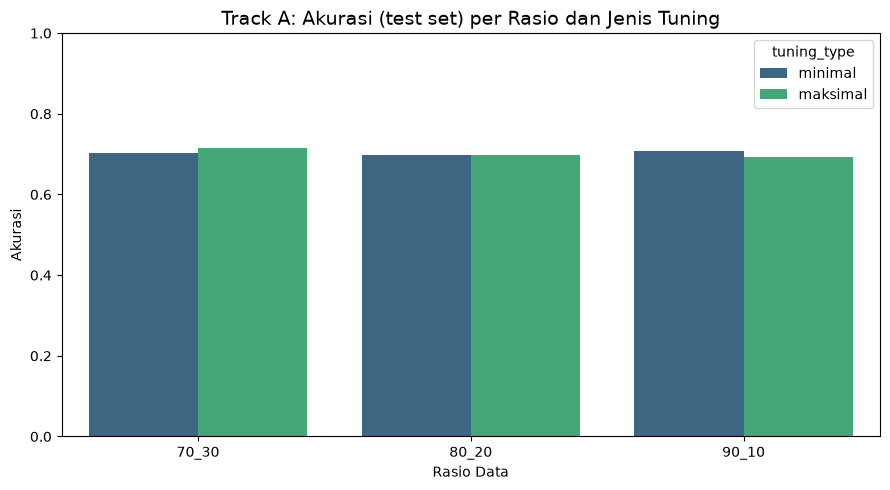

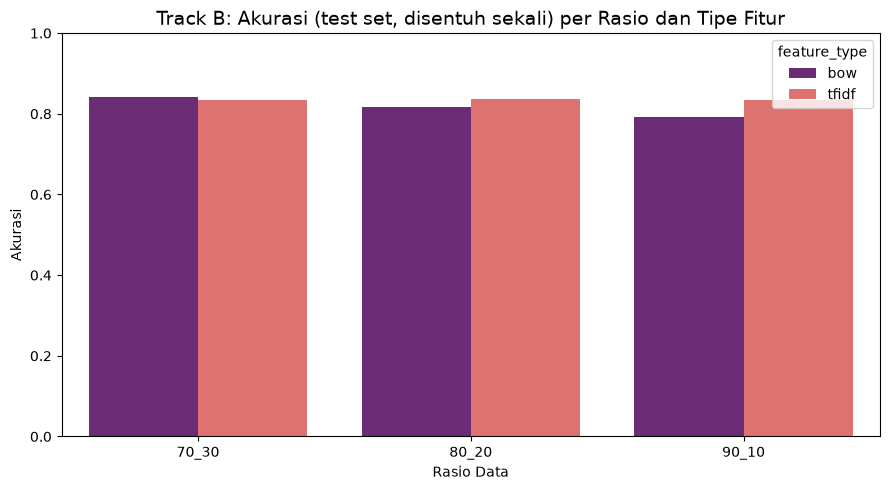

In [13]:
# ### Bar chart: Track A - akurasi per rasio x tuning-type
plt.figure(figsize=(9, 5))
plot_df_a = pd.DataFrame([
    {'ratio': r, 'tuning_type': t, 'accuracy': b['accuracy']}
    for (r, t), b in track_a_best.items()
])
sns.barplot(x='ratio', y='accuracy', hue='tuning_type', data=plot_df_a, palette='viridis')
plt.title('Track A: Akurasi (test set) per Rasio dan Jenis Tuning', fontsize=14)
plt.ylabel('Akurasi'); plt.xlabel('Rasio Data'); plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(PNG_DIR / 'track_a_accuracy_barplot.png', dpi=150)
plt.show()

# ### Bar chart: Track B - akurasi per rasio x tipe fitur
plt.figure(figsize=(9, 5))
plot_df_b = pd.DataFrame([
    {'ratio': r, 'feature_type': ft, 'accuracy': b['accuracy']}
    for (r, ft), b in track_b_best.items()
])
sns.barplot(x='ratio', y='accuracy', hue='feature_type', data=plot_df_b, palette='magma')
plt.title('Track B: Akurasi (test set, disentuh sekali) per Rasio dan Tipe Fitur', fontsize=14)
plt.ylabel('Akurasi'); plt.xlabel('Rasio Data'); plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(PNG_DIR / 'track_b_accuracy_barplot.png', dpi=150)
plt.show()


## 10. Perbandingan Track A vs Track B

Ringkasan akurasi dan metrik kelas hate-speech (`positif`) untuk konfigurasi terbaik masing-masing track,
supaya perbedaan hasil akibat perbaikan metodologi terlihat jelas dalam satu tabel.

In [14]:
def positif_metrics(report, positif_key='positif'):
    key = positif_key if positif_key in report else next(
        (k for k in report if k.lower() == positif_key), None)
    if key is None:
        return {'precision': None, 'recall': None, 'f1-score': None}
    return {k: report[key][k] for k in ('precision', 'recall', 'f1-score')}

summary_rows = []

# Track A: baris terbaik per tuning_type
for (ratio_name, tuning_type), best in track_a_best.items():
    pm = positif_metrics(best['report'])
    summary_rows.append({
        'track': 'A (original methodology)', 'ratio': ratio_name, 'config': tuning_type,
        'alpha': best['alpha'], 'accuracy': round(best['accuracy'], 4),
        'positif_precision': round(pm['precision'], 4) if pm['precision'] is not None else None,
        'positif_recall': round(pm['recall'], 4) if pm['recall'] is not None else None,
        'positif_f1': round(pm['f1-score'], 4) if pm['f1-score'] is not None else None,
    })

# Track B: baris untuk BoW dan TF-IDF
for (ratio_name, feat_type), best in track_b_best.items():
    pm = positif_metrics(best['report'])
    summary_rows.append({
        'track': 'B (fixed methodology)', 'ratio': ratio_name, 'config': feat_type,
        'alpha': best['alpha'], 'accuracy': round(best['accuracy'], 4),
        'positif_precision': round(pm['precision'], 4) if pm['precision'] is not None else None,
        'positif_recall': round(pm['recall'], 4) if pm['recall'] is not None else None,
        'positif_f1': round(pm['f1-score'], 4) if pm['f1-score'] is not None else None,
    })

comparison_df = pd.DataFrame(summary_rows).sort_values(['track', 'ratio', 'config']).reset_index(drop=True)
comparison_df.to_csv(CSV_DIR / 'track_a_vs_track_b_comparison.csv', index=False)
display(comparison_df)

print(f"\nTrack A - konfigurasi akurasi tertinggi: {track_a_overall_best_key}, "
      f"akurasi={track_a_best[track_a_overall_best_key]['accuracy']:.4f}")
print(f"Track B - konfigurasi akurasi tertinggi: {track_b_overall_best_key}, "
      f"akurasi={track_b_best[track_b_overall_best_key]['accuracy']:.4f}")
print(f"\nKesepakatan label lexicon (Track A) vs ground-truth (Track B): {agreement.mean():.1%}")


,track,ratio,config,alpha,accuracy,positif_precision,positif_recall,positif_f1
0,A (original methodology),70_30,maksimal,2.00,0.7151,0.7097,0.7979,0.7512
1,A (original methodology),70_30,minimal,0.80,0.7039,0.7122,0.7565,0.7337
2,A (original methodology),80_20,maksimal,1.00,0.6987,0.7080,0.7519,0.7293
3,A (original methodology),80_20,minimal,0.80,0.6987,0.7143,0.7364,0.7252
4,A (original methodology),90_10,maksimal,1.00,0.6917,0.7188,0.7077,0.7132
5,A (original methodology),90_10,minimal,0.80,0.7083,0.7344,0.7231,0.7287
6,B (fixed methodology),70_30,bow,3.00,0.8408,0.5833,0.1186,0.1972
7,B (fixed methodology),70_30,tfidf,2.00,0.8352,0.0000,0.0000,0.0000
8,B (fixed methodology),80_20,bow,0.01,0.8159,0.3810,0.2051,0.2667
9,B (fixed methodology),80_20,tfidf,1.00,0.8368,0.0000,0.0000,0.0000



Track A - konfigurasi akurasi tertinggi: ('70_30', 'maksimal'), akurasi=0.7151
Track B - konfigurasi akurasi tertinggi: ('70_30', 'bow'), akurasi=0.8408

Kesepakatan label lexicon (Track A) vs ground-truth (Track B): 49.9%


### Catatan interpretasi

- Bandingkan baris `positif_recall` antar kedua track: README notebook asli mendokumentasikan bahwa
  konfigurasi dengan akurasi tertinggi justru punya recall kelas hate-speech (`positif`) paling rendah — cek
  apakah pola yang sama muncul di Track B setelah label diperbaiki, stemmer diganti, dan kebocoran test set
  dihilangkan.
- Tabel kesepakatan label di Bagian 4 menunjukkan seberapa besar overlap antara label lexicon dan label
  ground-truth manusia — semakin rendah angka ini, semakin besar dampak isu #1 terhadap hasil Track A.
- Perbedaan akurasi Track B pada `bow` vs `tfidf` menunjukkan apakah representasi fitur berpengaruh untuk
  dataset dan model ini.
- Notebook ini **tidak** mengklaim salah satu track "benar" secara definitif untuk paper yang sudah
  dipublikasikan — tujuannya adalah menyediakan perbandingan yang transparan dan dapat direproduksi di luar
  hasil yang sudah dipublikasikan.